# ED408 — Statistical Machine Learning II Lab
## Experiment 11: L1, L2 and Elastic Net regularisation

All three minimise squared error plus a penalty on the coefficients (scikit-learn's parameterisation):

| Model | Objective | Effect |
|---|---|---|
| Ridge (L2) | $\lVert y-X\beta\rVert^2+\alpha\lVert\beta\rVert_2^2$ | shrinks all coefficients smoothly, none become exactly 0 |
| Lasso (L1) | $\frac{1}{2n}\lVert y-X\beta\rVert^2+\alpha\lVert\beta\rVert_1$ | sets some coefficients exactly to 0 (feature selection) |
| Elastic Net | $\frac{1}{2n}\lVert y-X\beta\rVert^2+\alpha\rho\lVert\beta\rVert_1+\frac{\alpha(1-\rho)}{2}\lVert\beta\rVert_2^2$ | sparse like Lasso, but tends to keep correlated features together |

**Dataset.** We use a synthetic regression problem so the true coefficients are known. There are 40 correlated features ($\mathrm{corr}(x_i,x_j)=0.7^{|i-j|}$), only 7 of them truly non-zero, and just **60 training samples**. With that few samples, plain least squares overfits badly. At the end we repeat the comparison on the real *diabetes* dataset from scikit-learn.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
import pandas as pd
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV, Ridge, lasso_path, enet_path
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

rng = np.random.default_rng(0)
p = 40
Sigma = 0.7 ** np.abs(np.subtract.outer(np.arange(p), np.arange(p)))
beta_true = np.zeros(p)
beta_true[[0, 1, 2, 10, 11, 20, 30]] = [3, -2, 1.5, 2.5, 2.5, -3, 1]

def make_data(n):
    X = rng.multivariate_normal(np.zeros(p), Sigma, n)
    return X, X @ beta_true + rng.normal(0, 2.0, n)

X_tr, y_tr = make_data(60)
X_te, y_te = make_data(2000)
sc = StandardScaler().fit(X_tr)          # penalties assume features on the same scale
X_tr, X_te = sc.transform(X_tr), sc.transform(X_te)
print("train", X_tr.shape, " test", X_te.shape, " true non-zero coefficients:", np.count_nonzero(beta_true))

train (60, 40)  test (2000, 40)  true non-zero coefficients: 7


### Penalty geometry
The L1 ball has corners on the axes. The elliptical loss contours usually touch it first at a corner, and that is why Lasso gives exact zeros. The L2 ball is round, so the touching point almost never lies on an axis.

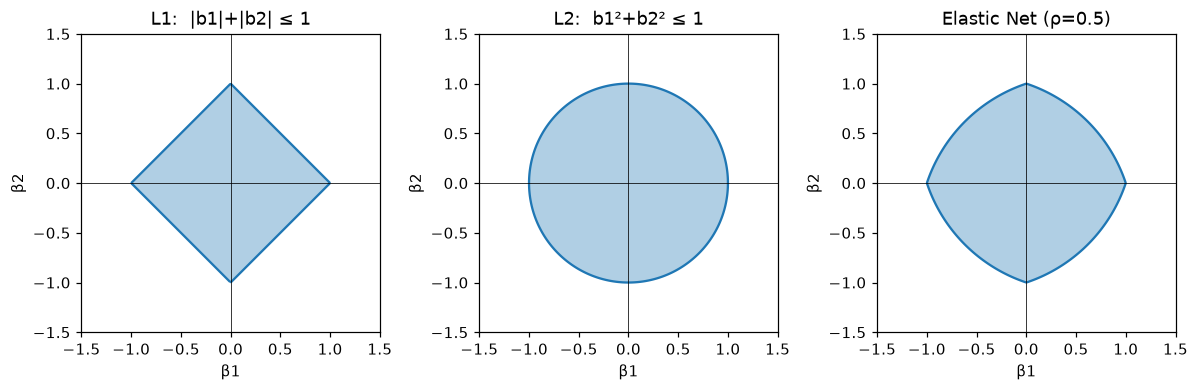

In [2]:
t = np.linspace(0, 2*np.pi, 400)
b1, b2 = np.cos(t), np.sin(t)
fig, ax = plt.subplots(1, 3, figsize=(11, 3.6))
for a, (name, norm) in zip(ax, [("L1:  |b1|+|b2| ≤ 1", lambda u, v: np.abs(u) + np.abs(v)),
                                ("L2:  b1²+b2² ≤ 1", lambda u, v: u**2 + v**2),
                                ("Elastic Net (ρ=0.5)", lambda u, v: 0.5*(np.abs(u)+np.abs(v)) + 0.5*(u**2+v**2))]):
    gx, gy = np.meshgrid(np.linspace(-1.5, 1.5, 300), np.linspace(-1.5, 1.5, 300))
    a.contourf(gx, gy, norm(gx, gy), levels=[0, 1], colors=["tab:blue"], alpha=0.35)
    a.contour(gx, gy, norm(gx, gy), levels=[1], colors="tab:blue")
    a.axhline(0, c="k", lw=0.5); a.axvline(0, c="k", lw=0.5)
    a.set(title=name, aspect="equal", xlabel="β1", ylabel="β2")
plt.tight_layout(); plt.show()

### Models with the penalty strength chosen by 5-fold cross-validation

In [3]:
alphas = np.logspace(-3, 3, 100)
models = {
    "OLS (no penalty)": LinearRegression(),
    "Ridge (L2)":       RidgeCV(alphas=alphas, cv=5),
    "Lasso (L1)":       LassoCV(cv=5, max_iter=50000, random_state=0),
    "Elastic Net":      ElasticNetCV(l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9], cv=5, max_iter=50000, random_state=0),
}
rows, coefs = [], {}
true_support = beta_true != 0
for name, m in models.items():
    m.fit(X_tr, y_tr)
    pred = m.predict(X_te)
    nz = np.abs(m.coef_) > 1e-8
    coefs[name] = m.coef_
    rows.append({"model": name,
                 "alpha": getattr(m, "alpha_", 0),
                 "l1_ratio": getattr(m, "l1_ratio_", "—"),
                 "test MSE": mean_squared_error(y_te, pred),
                 "test R²": r2_score(y_te, pred),
                 "non-zero coefs": nz.sum(),
                 "true features kept": (nz & true_support).sum(),
                 "noise features kept": (nz & ~true_support).sum()})
results = pd.DataFrame(rows).set_index("model")
results.round(3)

,alpha,l1_ratio,test MSE,test R²,non-zero coefs,true features kept,noise features kept
model,,,,,,,
OLS (no penalty),0.000,—,22.021,0.470,40,7,33
Ridge (L2),3.275,—,9.867,0.763,40,7,33
Lasso (L1),0.102,—,6.826,0.836,25,7,18
Elastic Net,0.105,0.9,7.078,0.830,25,7,18


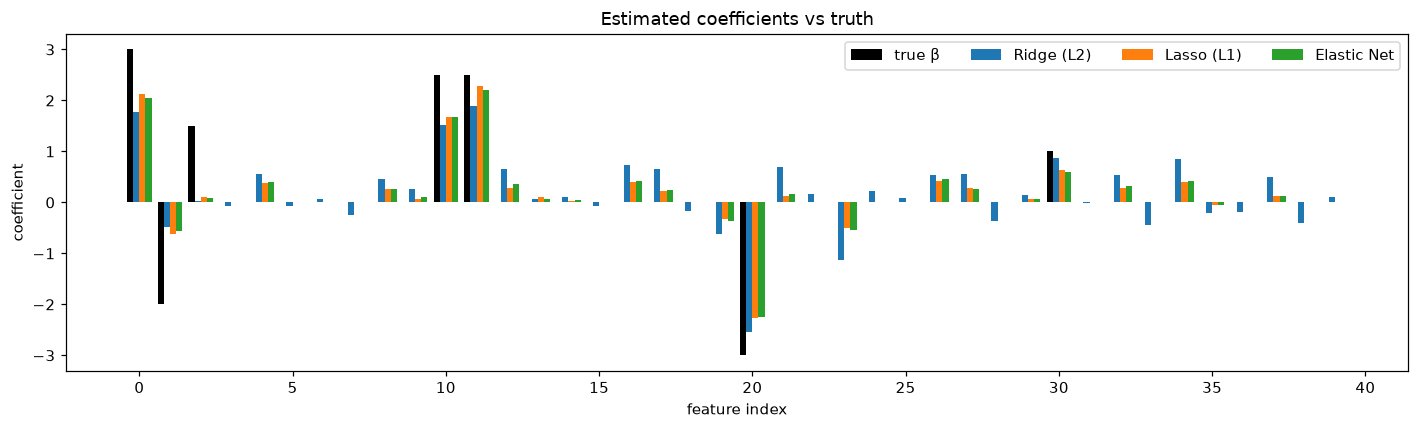

In [4]:
fig, ax = plt.subplots(figsize=(13, 4))
w = 0.2
idx = np.arange(p)
ax.bar(idx - 1.5*w, beta_true, w, label="true β", color="k")
for i, name in enumerate(["Ridge (L2)", "Lasso (L1)", "Elastic Net"]):
    ax.bar(idx + (i - 0.5)*w, coefs[name], w, label=name)
ax.set(xlabel="feature index", ylabel="coefficient", title="Estimated coefficients vs truth")
ax.legend(ncol=4); plt.tight_layout(); plt.show()

### Regularisation paths
Each line shows one coefficient as the penalty $\alpha$ grows. The 7 truly relevant features are drawn in colour and the 33 noise features in grey.

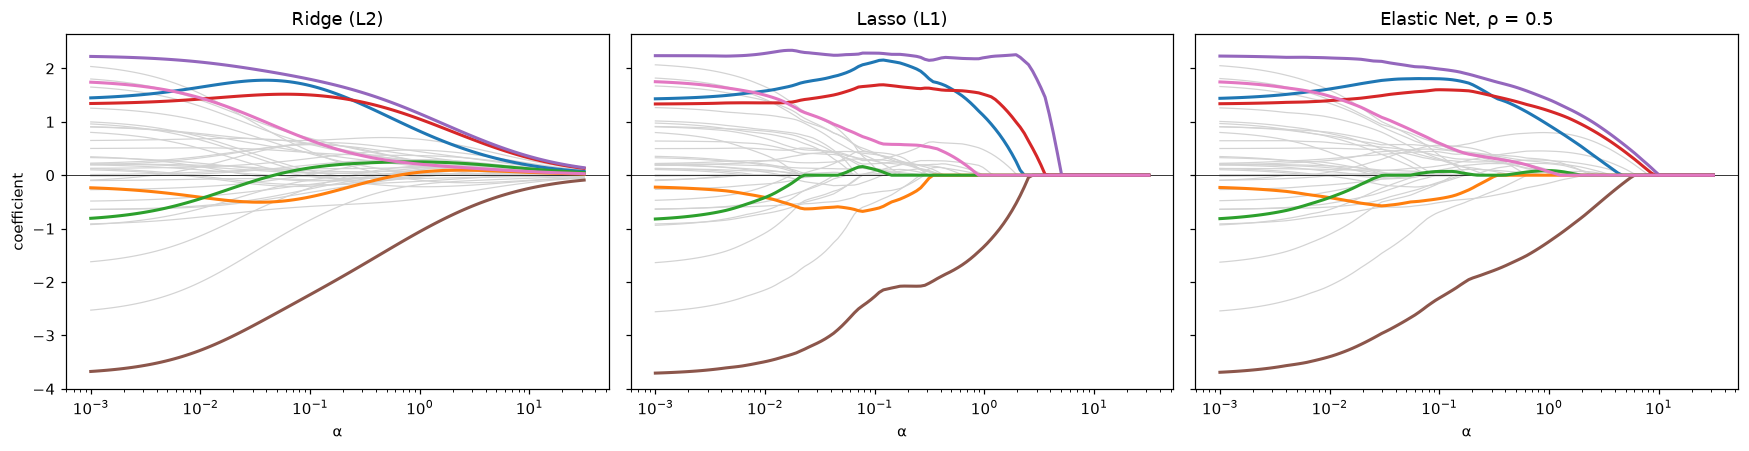

alpha=0.01  non-zero  ridge=40  lasso=34  enet=38
alpha=0.1   non-zero  ridge=40  lasso=25  enet=28
alpha=0.5   non-zero  ridge=40  lasso=10  enet=21
alpha=1.0   non-zero  ridge=40  lasso= 6  enet=20


In [5]:
path_alphas = np.logspace(1.5, -3, 120)          # descending, as lasso_path/enet_path expect
ridge_path = np.array([Ridge(alpha=a * len(y_tr)).fit(X_tr, y_tr).coef_ for a in path_alphas]).T  # rescaled to match lasso's 1/(2n) loss
_, lasso_coefs, _ = lasso_path(X_tr, y_tr - y_tr.mean(), alphas=path_alphas, max_iter=50000)
_, enet_coefs, _ = enet_path(X_tr, y_tr - y_tr.mean(), l1_ratio=0.5, alphas=path_alphas, max_iter=50000)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for a, (title, C) in zip(ax, [("Ridge (L2)", ridge_path), ("Lasso (L1)", lasso_coefs), ("Elastic Net, ρ = 0.5", enet_coefs)]):
    for j in range(p):
        a.plot(path_alphas, C[j], c=None if true_support[j] else "lightgray",
               lw=2 if true_support[j] else 0.8, zorder=3 if true_support[j] else 1)
    a.set(xscale="log", xlabel="α", title=title); a.axhline(0, c="k", lw=0.5)
ax[0].set_ylabel("coefficient")
plt.tight_layout(); plt.show()

# how many coefficients survive as alpha grows
for a_ in [0.01, 0.1, 0.5, 1.0]:
    k = np.argmin(np.abs(path_alphas - a_))
    print(f"alpha={a_:<5} non-zero  ridge={np.sum(np.abs(ridge_path[:, k]) > 1e-8):2d}  "
          f"lasso={np.sum(np.abs(lasso_coefs[:, k]) > 1e-8):2d}  enet={np.sum(np.abs(enet_coefs[:, k]) > 1e-8):2d}")

### Real data: scikit-learn diabetes dataset (442 patients, 10 features)

In [6]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

Xd, yd = load_diabetes(return_X_y=True, as_frame=True)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.3, random_state=0)
sc_d = StandardScaler().fit(Xd_tr)
Xd_tr_s, Xd_te_s = sc_d.transform(Xd_tr), sc_d.transform(Xd_te)

rows, coef_table = [], {}
for name, m in {"OLS": LinearRegression(),
                "Ridge": RidgeCV(alphas=alphas, cv=5),
                "Lasso": LassoCV(cv=5, random_state=0),
                "Elastic Net": ElasticNetCV(l1_ratio=[0.1, 0.5, 0.9], cv=5, random_state=0)}.items():
    m.fit(Xd_tr_s, yd_tr)
    coef_table[name] = m.coef_
    rows.append({"model": name, "alpha": getattr(m, "alpha_", 0),
                 "test MSE": mean_squared_error(yd_te, m.predict(Xd_te_s)),
                 "test R²": r2_score(yd_te, m.predict(Xd_te_s)),
                 "non-zero coefs": int(np.sum(np.abs(m.coef_) > 1e-8))})
display(pd.DataFrame(rows).set_index("model").round(3))
pd.DataFrame(coef_table, index=Xd.columns).round(2)

,alpha,test MSE,test R²,non-zero coefs
model,,,,
OLS,0.000,3097.119,0.393,10
Ridge,23.101,3075.153,0.397,10
Lasso,1.300,3116.221,0.389,7
Elastic Net,0.544,3086.435,0.395,10


,OLS,Ridge,Lasso,Elastic Net
age,-2.53,-1.99,-0.52,-1.43
sex,-9.21,-8.43,-6.94,-7.81
bmi,27.98,26.54,27.84,26.82
bp,12.99,12.58,11.18,12.05
s1,-23.91,-3.52,-5.84,-2.76
s2,11.50,-4.52,-0.00,-3.74
s3,-3.36,-10.96,-10.82,-11.89
s4,4.24,3.80,0.00,1.57
s5,35.44,25.15,28.43,25.67
s6,1.37,2.32,0.00,1.65


**Observations.**
* **OLS overfits.** With 40 features and only 60 samples it reaches test $R^2=0.47$ (MSE 22.0). Every penalty helps: Ridge gets $R^2=0.76$; Lasso and Elastic Net get $R^2\approx0.83$ and cut the test MSE by about 3×.
* **Ridge shrinks but never selects.** All 40 coefficients stay non-zero at every $\alpha$. In the path plot they shrink smoothly towards 0 together.
* **Lasso selects.** Coefficients hit exactly 0 one by one as $\alpha$ grows (34 → 25 → 10 → 6 non-zero for $\alpha=0.01, 0.1, 0.5, 1$). At the CV-chosen $\alpha$ it keeps all 7 true features and drops 15 noise features. CV optimises prediction error, not support recovery, so it still keeps some small noise coefficients.
* **Elastic Net sits in between.** For the same $\alpha$ it keeps more features than Lasso (20 vs 6 at $\alpha=1$) and its path is smoother. The L2 part spreads weight across correlated features instead of picking one arbitrarily. Here CV chose $\rho=0.9$, i.e. mostly L1, so its result is close to Lasso's.
* Lasso and Elastic Net both nearly zero out true feature 2 ($\beta=1.5$). It is strongly correlated with its neighbours 0 and 1, which absorb its effect. This is the classic difficulty of L1 with correlated designs.
* **Diabetes (n=442, p=10).** Here $n\gg p$, so OLS does not overfit and all four models score about the same ($R^2\approx0.39$–$0.40$). Regularisation still helps interpretation: Lasso removes `s2`, `s4` and `s6`, and every penalty shrinks the unstable, collinear `s1`/`s2` pair (−23.9 / +11.5 under OLS) to small values.